In [ ]:
import pandas as pd
import numpy as np


# SHEET 1

Step 1 : Melihat anomali dalam data

In [ ]:
# BACA SHEET
df = pd.read_excel('data_latihan_bi_kotor.xlsx', sheet_name="Transaksi_BI")
df

,Tanggal,Kode_Transaksi,Kantor_BI,Kanal_Pembayaran,Jenis_Transaksi,Kategori,Nilai_Transaksi,Biaya_Admin
0,2024-03-01,TRX000001,KPwBI DKI Jakarta,QRIS,Pemerintah,Penerimaan,-582831000,2500.0
1,2024-10-20,TRX000002,KPwBI Bali,Tunai,Individu,Pengeluaran,657.755.000,0.0
2,2024-01-02,TRX000003,KPwBI DKI Jakarta,Kartu Debit,Individu,Pengeluaran,NaN,2500.0
3,2024-12-16,TRX000004,KPwBI Bali,Tunai,Korporasi,Penerimaan,-283496000,0.0
4,01/07/2024,TRX000005,KPwBI DKI Jakarta,Kartu Kredit,Korporasi,Penerimaan,651078000,5000.0
...,...,...,...,...,...,...,...,...
195,2024-01-01,TRX000191,KPwBI Bali,QRIS,Pemerintah,Penerimaan,716836000,0.0
196,24/08/2024,TRX000192,KPwBI Sumatera Utara,Tunai,Pemerintah,Penerimaan,136519000,0.0
197,2024-01-16,TRX000193,KPwBI Bali,Transfer BI-FAST,UMKM,Penerimaan,174797000,2500.0
198,2024-05-16,TRX000077,KPwBI Jawa Barat,Transfer BI-FAST,Korporasi,Pengeluaran,400560000,2500.0


In [ ]:
print(df.head(10).to_string())

      Tanggal Kode_Transaksi           Kantor_BI Kanal_Pembayaran Jenis_Transaksi     Kategori Nilai_Transaksi  Biaya_Admin
0  2024-03-01      TRX000001   KPwBI DKI Jakarta             QRIS      Pemerintah   Penerimaan      -582831000       2500.0
1  2024-10-20      TRX000002          KPwBI Bali            Tunai        Individu  Pengeluaran     657.755.000          0.0
2  2024-01-02      TRX000003   KPwBI DKI Jakarta      Kartu Debit        Individu  Pengeluaran             NaN       2500.0
3  2024-12-16      TRX000004          KPwBI Bali            Tunai       Korporasi   Penerimaan      -283496000          0.0
4  01/07/2024      TRX000005  KPwBI DKI Jakarta      Kartu Kredit       Korporasi   Penerimaan       651078000       5000.0
5  2024-08-22      TRX000006   KPwBI Jawa Timur              QRIS       Korporasi  Pengeluaran       633874000       2500.0
6  29/12/2024      TRX000007   KPwBI DKI Jakarta            tunai        Individu   Penerimaan       415504000          0.0
7  29/02

In [ ]:
# Lihat tipe data setiap kolom
print(df.dtypes)

Tanggal              object
Kode_Transaksi       object
Kantor_BI            object
Kanal_Pembayaran     object
Jenis_Transaksi      object
Kategori             object
Nilai_Transaksi      object
Biaya_Admin         float64
dtype: object


In [ ]:
# Cek missing value

print(df.isnull().sum())

Tanggal             0
Kode_Transaksi      0
Kantor_BI           4
Kanal_Pembayaran    4
Jenis_Transaksi     3
Kategori            2
Nilai_Transaksi     5
Biaya_Admin         6
dtype: int64


In [ ]:
df.columns.to_list()

['Tanggal',
 'Kode_Transaksi',
 'Kantor_BI',
 'Kanal_Pembayaran',
 'Jenis_Transaksi',
 'Kategori',
 'Nilai_Transaksi',
 'Biaya_Admin']

In [ ]:
# Lihat unique value tiap kolom
for nama_kolom in ['Tanggal',
 'Kode_Transaksi',
 'Kantor_BI',
 'Kanal_Pembayaran',
 'Jenis_Transaksi',
 'Kategori',
 'Nilai_Transaksi',
 'Biaya_Admin']:
 print(nama_kolom, ":->", list(df[nama_kolom].unique()))

Tanggal :-> ['2024-03-01', '2024-10-20', '2024-01-02', '2024-12-16', '01/07/2024', '2024-08-22', '29/12/2024', '29/02/2024', '2024-09-25', '2024-03-07', '03/09/2024', '2024-12-31', '2024-12-08', '09/08/2024', '03/07/2024', '2024-08-10', '20/02/2024', '2024-04-03', '2024-09-12', '08/01/2024', datetime.datetime(2024, 3, 2, 0, 0), '2024-01-03', '30 August 2024', '27/10/2024', '2024-11-26', datetime.datetime(2024, 6, 16, 0, 0), '19/10/2024', datetime.datetime(2024, 11, 15, 0, 0), '2024-01-18', datetime.datetime(2024, 11, 24, 0, 0), '21/09/2024', '2024-05-19', datetime.datetime(2024, 4, 5, 0, 0), '27 August 2024', '2024-04-19', '2024-10-06', '14 October 2024', datetime.datetime(2024, 10, 18, 0, 0), '19/02/2024', '2024-04-04', '2024-06-10', datetime.datetime(2024, 1, 8, 0, 0), '10 June 2024', '2024-08-06', '2024-07-18', '2024-05-24', datetime.datetime(2024, 6, 12, 0, 0), '27/02/2024', '15 January 2024', datetime.datetime(2024, 5, 2, 0, 0), '2024-05-10', '2024-05-15', '10 October 2024', '02/1

In [ ]:
df.describe()

,Biaya_Admin
count,194.000000
mean,1595.360825
std,1777.064332
min,-2500.000000
25%,0.000000
50%,2500.000000
75%,2500.000000
max,7500.000000


Move to Gemini

In [ ]:
# ==========================================
# CELL 1: Pembersihan dan Format Kolom Tanggal (Perbaikan)
# ==========================================
import pandas as pd
from datetime import datetime

jumlah_baris_awal = len(df)
gagal_baca = 0
tanggal_bersih = []

# Daftar format tanggal yang umum digunakan
format_tanggal = [
    "%Y-%m-%d",      # 2024-03-01
    "%d/%m/%Y",      # 01/07/2024
    "%m/%d/%Y",      # 07/01/2024 (jika ada format US)
    "%d %B %Y",      # 29 Desember 2024 / 29 December 2024
    "%d %b %Y",      # 29 Des 2024 / 29 Dec 2024
]

# Kamus konversi bulan Bahasa Indonesia ke Inggris
bulan_indo = {
    "januari": "january", "februari": "february", "maret": "march",
    "april": "april", "mei": "may", "juni": "june",
    "juli": "july", "agustus": "august", "september": "september",
    "oktober": "october", "november": "november", "desember": "december",
    "ags": "aug", "des": "dec"
}

for val in df["Tanggal"]:
    # 1. Jika sudah bertipe datetime/timestamp
    if isinstance(val, (pd.Timestamp, datetime)):
        tanggal_bersih.append(pd.to_datetime(val))
        continue

    # 2. Jika bernilai null / NaN
    if pd.isna(val):
        tanggal_bersih.append(pd.NaT)
        gagal_baca += 1
        continue

    # 3. Bersihkan spasi tersembunyi dan ubah nama bulan Indo ke Inggris jika ada
    val_str = str(val).strip().lower()
    for indo, ing in bulan_indo.items():
        if indo in val_str:
            val_str = val_str.replace(indo, ing)
            break

    parsed = None

    # 4. Coba parsing menggunakan Python datetime bawaan
    for fmt in format_tanggal:
        try:
            parsed = datetime.strptime(val_str, fmt)
            break
        except ValueError:
            pass

    # 5. Jika format manual di atas gagal, gunakan fleksibilitas pd.to_datetime standar
    if parsed is None:
        try:
            parsed = pd.to_datetime(val_str, dayfirst=True)
        except Exception:
            parsed = None

    # Simpan hasil
    if parsed is not None:
        tanggal_bersih.append(pd.to_datetime(parsed))
    else:
        tanggal_bersih.append(pd.NaT)
        gagal_baca += 1

# Timpa kolom Tanggal
df["Tanggal"] = tanggal_bersih

print("Pembersihan tanggal selesai.")
print(f"Jumlah nilai yang gagal dibaca sebagai tanggal: {gagal_baca}")

Pembersihan tanggal selesai.
Jumlah nilai yang gagal dibaca sebagai tanggal: 0


In [ ]:
# ==========================================
# CELL 2: Pembersihan Kolom Teks (Kategori)
# ==========================================
kolom_teks = ["Kantor_BI", "Kanal_Pembayaran", "Jenis_Transaksi", "Kategori"]

for col in kolom_teks:
    # 1. Buang spasi di awal dan akhir
    df[col] = df[col].astype(str).str.strip()

    # kembalikan nilai NaN yang terubah jadi string 'nan'
    df[col] = df[col].replace(["nan", "NaN", "None", ""], pd.NA)

    # 2. Cari bentuk penulisan yang paling sering muncul (modus) untuk tiap variasi huruf
    # Buat pemetaan teks lowercase -> teks paling sering muncul
    non_null_series = df[col].dropna()
    if not non_null_series.empty:
        # Hitung frekuensi tiap bentuk penulisan
        counts = non_null_series.value_counts()

        # Group berdasarkan huruf kecil untuk menemukan opsi paling dominan
        mapping_modus = {}
        for val in counts.index:
            val_lower = val.lower()
            if val_lower not in mapping_modus:
                mapping_modus[val_lower] = val

        # Terapkan penulisan paling sering ke seluruh kolom
        df[col] = df[col].map(
            lambda x: mapping_modus.get(x.lower(), x) if pd.notna(x) else x
        )

print("Pembersihan kolom teks selesai.")

Pembersihan kolom teks selesai.


In [ ]:
# ==========================================
# CELL 3: Konversi Nilai_Transaksi dan Biaya_Admin
# ==========================================


def bersihkan_ke_angka(val):
    if pd.isna(val):
        return None

    # Jika sudah angka (int atau float)
    if isinstance(val, (int, float)):
        return float(val)

    # Jika berupa teks / string
    val_str = str(val).strip()

    # Hapus simbol 'Rp' dan spasi
    val_str = val_str.replace("Rp", "").replace("rp", "").strip()

    # Hapus titik pemisah ribuan
    val_str = val_str.replace(".", "")

    # Ubah koma desimal jadi titik (jika ada)
    val_str = val_str.replace(",", ".")

    try:
        return float(val_str)
    except ValueError:
        return None


# Terapkan pembersihan
df["Nilai_Transaksi"] = df["Nilai_Transaksi"].apply(bersihkan_ke_angka)
df["Biaya_Admin"] = df["Biaya_Admin"].apply(bersihkan_ke_angka)

print("Konversi kolom angka selesai.")

Konversi kolom angka selesai.


In [ ]:
# ==========================================
# CELL 4: Penanganan Duplikat, Nilai Negatif, Ekstrem, dan Sel Kosong
# ==========================================
# 1. Hapus duplikat persis
df = df.drop_duplicates().reset_index(drop=True)

# 2. Ubah nilai negatif pada Nilai_Transaksi dan Biaya_Admin menjadi kosong (NaN)
df.loc[df["Nilai_Transaksi"] < 0, "Nilai_Transaksi"] = pd.NA
df.loc[df["Biaya_Admin"] < 0, "Biaya_Admin"] = pd.NA

# 3. Handling nilai ekstrem (Outlier IQR 3x) pada Nilai_Transaksi
Q1 = df["Nilai_Transaksi"].quantile(0.25)
Q3 = df["Nilai_Transaksi"].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - (3 * IQR)
batas_atas = Q3 + (3 * IQR)

df.loc[
    (df["Nilai_Transaksi"] < batas_bawah)
    | (df["Nilai_Transaksi"] > batas_atas),
    "Nilai_Transaksi",
] = pd.NA

# 4. Imputasi sel kosong
# Angka: isi dengan Median
df["Nilai_Transaksi"] = df["Nilai_Transaksi"].fillna(
    df["Nilai_Transaksi"].median()
)
df["Biaya_Admin"] = df["Biaya_Admin"].fillna(df["Biaya_Admin"].median())

# Teks & Tanggal: isi dengan Modus (nilai paling sering)
for col in ["Tanggal"] + kolom_teks:
    modus_val = df[col].mode()[0]
    df[col] = df[col].fillna(modus_val)

print("Penanganan duplikat, outlier, dan missing value selesai.")

Penanganan duplikat, outlier, dan missing value selesai.


In [ ]:
# ==========================================
# CELL 5: Pengecekan Akhir
# ==========================================
jumlah_baris_akhir = len(df)
baris_dihapus = jumlah_baris_awal - jumlah_baris_akhir

print("=== RINGKASAN PEMBERSIHAN DATA ===")
print(f"Jumlah baris awal  : {jumlah_baris_awal}")
print(f"Jumlah baris akhir : {jumlah_baris_akhir}")
print(f"Baris duplikat dihapus : {baris_dihapus}")
print("\n--- Sisa Sel Kosong ---")
print(df.isna().sum())

print("\n--- Rentang Kolom Angka ---")
print(
    f"Nilai_Transaksi : Min = {df['Nilai_Transaksi'].min():,.0f} | Max = {df['Nilai_Transaksi'].max():,.0f}"
)
print(
    f"Biaya_Admin     : Min = {df['Biaya_Admin'].min():,.0f} | Max = {df['Biaya_Admin'].max():,.0f}"
)

print("\n--- Rentang Tanggal ---")
print(
    f"Tanggal Paling Awal  : {df['Tanggal'].min().strftime('%Y-%m-%d')}"
)
print(
    f"Tanggal Paling Akhir : {df['Tanggal'].max().strftime('%Y-%m-%d')}"
)

print("\n--- Nilai Unik Kolom Kategori ---")
for col in kolom_teks:
    print(f"{col}: {df[col].unique().tolist()}")

=== RINGKASAN PEMBERSIHAN DATA ===
Jumlah baris awal  : 200
Jumlah baris akhir : 194
Baris duplikat dihapus : 6

--- Sisa Sel Kosong ---
Tanggal             0
Kode_Transaksi      0
Kantor_BI           0
Kanal_Pembayaran    0
Jenis_Transaksi     0
Kategori            0
Nilai_Transaksi     0
Biaya_Admin         0
dtype: int64

--- Rentang Kolom Angka ---
Nilai_Transaksi : Min = 9,340,000 | Max = 893,436,000
Biaya_Admin     : Min = 0 | Max = 7,500

--- Rentang Tanggal ---
Tanggal Paling Awal  : 2024-01-01
Tanggal Paling Akhir : 2024-12-31

--- Nilai Unik Kolom Kategori ---
Kantor_BI: ['KPwBI DKI Jakarta', 'KPwBI Bali', 'KPwBI Jawa Timur', 'BI Pusat', 'KPwBI Jawa Barat', 'KPwBI Sumatera Utara']
Kanal_Pembayaran: ['QRIS', 'Tunai', 'Kartu Debit', 'Kartu Kredit', 'Transfer BI-FAST']
Jenis_Transaksi: ['Pemerintah', 'Individu', 'Korporasi', 'UMKM']
Kategori: ['Penerimaan', 'Pengeluaran']


In [ ]:
df.dtypes

,0
Tanggal,datetime64[ns]
Kode_Transaksi,object
Kantor_BI,object
Kanal_Pembayaran,object
Jenis_Transaksi,object
Kategori,object
Nilai_Transaksi,float64
Biaya_Admin,float64


## Simpan hasil pembersihan ke dalam variabel baru

In [ ]:
df_transaksi = df.copy()

# Sheet 2

In [ ]:
# Kenalan dengan dataset

In [ ]:
df = pd.read_excel("data_latihan_bi_kotor.xlsx", sheet_name="Survei_Persepsi")
print(df.head(10).to_string())

  ID_Responden usia Jenis Kelamin         Domisili          Pekerjaan  Frekuensi_Gunakan_QRIS    Kepuasan_Layanan_QRIS  persepsi_keamanan_transaksi  Pengetahuan BI FAST  Niat_Menggunakan_Lagi  loyalitas
0        R0001   46     Laki-laki        Jawa Barat     PNS/TNI/Polri                        7                     5.0                            4                    4                      1        3.0
1        R0002   49     Laki-laki       Jawa Tengah     PNS/TNI/Polri                        5                     5.0                            1                    2                      2        4.0
2        R0003   21     Laki-laki  Sulawesi Selatan   Pegawai Swasta                         7                     1.0                            5                    4                      1        3.0
3        R0004   53     Laki-laki       Jawa Tengah  Ibu Rumah Tangga                        7                     5.0                            5                    1                    

In [ ]:
print(df.dtypes)

ID_Responden                    object
usia                            object
Jenis Kelamin                   object
Domisili                        object
Pekerjaan                       object
Frekuensi_Gunakan_QRIS           int64
 Kepuasan_Layanan_QRIS         float64
persepsi_keamanan_transaksi      int64
Pengetahuan BI FAST              int64
Niat_Menggunakan_Lagi            int64
loyalitas                      float64
dtype: object


In [ ]:
print(df.isna().sum())

ID_Responden                   0
usia                           5
Jenis Kelamin                  0
Domisili                       3
Pekerjaan                      4
Frekuensi_Gunakan_QRIS         0
 Kepuasan_Layanan_QRIS         6
persepsi_keamanan_transaksi    0
Pengetahuan BI FAST            0
Niat_Menggunakan_Lagi          0
loyalitas                      5
dtype: int64


In [ ]:
df.columns

Index(['ID_Responden', 'usia', 'Jenis Kelamin', 'Domisili ', 'Pekerjaan',
       'Frekuensi_Gunakan_QRIS ', ' Kepuasan_Layanan_QRIS',
       'persepsi_keamanan_transaksi', 'Pengetahuan BI FAST',
       'Niat_Menggunakan_Lagi', 'loyalitas'],
      dtype='object')

In [ ]:
#cek isi tiap kolom/unique value tiap kolom

for nama_kolom in df.columns:
  if nama_kolom == "ID_Responden":
    continue

  print(nama_kolom)
  print(df[nama_kolom].unique().tolist())
  print()

usia
[46, 49, 21, 53, 19, 43, 55, 61, 250, 36, 20, 18, 32, 51, -5, 58, 59, nan, 26, 47, 42, 22, 34, 48, 28, 35, 31, 23, 60, 54, 44, 29, 57, 45, 41, 39, 999, 24, 40, 52, '62 tahun', 38, 62, 30, '51 tahun', 56, 25, 7, 50, 37, '46 tahun']

Jenis Kelamin
['Laki-laki', 'Perempuan', 'P', 'Perempuan ', 'L', 'laki-laki']

Domisili 
['Jawa Barat', 'Jawa Tengah', 'Sulawesi Selatan', 'Jabar', 'Bali', 'Jawa Timur', 'Sumatera Utara', 'DKI Jakarta', 'Banten', nan, 'Jakarta', 'jawa barat', 'jakarta ']

Pekerjaan
['PNS/TNI/Polri', 'Pegawai Swasta ', 'Ibu Rumah Tangga', 'Pegawai Swasta', 'Wirausaha', 'Lainnya', 'wirausaha', 'Pelajar/Mahasiswa', nan, 'PNS']

Frekuensi_Gunakan_QRIS 
[7, 5, 3, 4, 2, 1, 6, 11]

 Kepuasan_Layanan_QRIS
[5.0, 1.0, 3.0, nan, 4.0, 2.0, 9.0]

persepsi_keamanan_transaksi
[4, 1, 5, 2, 3, 9]

Pengetahuan BI FAST
[4, 2, 1, 3, 5, 0]

Niat_Menggunakan_Lagi
[1, 2, 3, 5, 4, 9]

loyalitas
[3.0, 4.0, 2.0, 1.0, 5.0, nan]



GEMINI


In [ ]:
# ==========================================
# CELL 1: Standarisasi Nama Kolom
# ==========================================

# Simpan jumlah baris awal untuk pengecekan di akhir
jumlah_baris_awal = len(df)

# Daftar nama kolom baru yang baku
nama_kolom_baru = [
    "ID_Responden",
    "Usia",
    "Jenis_Kelamin",
    "Domisili",
    "Pekerjaan",
    "Frekuensi_Gunakan_QRIS",
    "Kepuasan_Layanan_QRIS",
    "Persepsi_Keamanan_Transaksi",
    "Pengetahuan_BI_FAST",
    "Niat_Menggunakan_Lagi",
    "Loyalitas",
]

# Ganti nama kolom langsung
df.columns = nama_kolom_baru

print("Langkah 1 Selesai: Nama kolom berhasil diperbarui.")
print("Daftar kolom baru:", df.columns.tolist())

Langkah 1 Selesai: Nama kolom berhasil diperbarui.
Daftar kolom baru: ['ID_Responden', 'Usia', 'Jenis_Kelamin', 'Domisili', 'Pekerjaan', 'Frekuensi_Gunakan_QRIS', 'Kepuasan_Layanan_QRIS', 'Persepsi_Keamanan_Transaksi', 'Pengetahuan_BI_FAST', 'Niat_Menggunakan_Lagi', 'Loyalitas']


In [ ]:
# ==========================================
# CELL 2: Menghapus Baris Duplikat Persis
# ==========================================

# Hitung jumlah baris sebelum dihapus
baris_sebelum = len(df)

# Hapus duplikat persis dan reset index
df = df.drop_duplicates().reset_index(drop=True)

# Hitung jumlah baris duplikat yang terhapus
jumlah_duplikat = baris_sebelum - len(df)

print(f"Langkah 2 Selesai: {jumlah_duplikat} baris duplikat dihapus.")

Langkah 2 Selesai: 4 baris duplikat dihapus.


In [ ]:
# ==========================================
# CELL 3: Pembersihan Kolom Usia
# ==========================================
import pandas as pd

jumlah_teks_dihapus = 0
jumlah_usia_tidak_wajar = 0
usia_bersih = []

for val in df["Usia"]:
    if pd.isna(val):
        usia_bersih.append(pd.NA)
        continue

    # Konversi ke string dan buang spasi
    val_str = str(val).strip().lower()

    # Hapus tulisan "tahun" jika ada
    if "tahun" in val_str:
        val_str = val_str.replace("tahun", "").strip()
        jumlah_teks_dihapus += 1

    # Coba ubah ke angka
    try:
        angka_usia = float(val_str)
        # Cek batas usia wajar (17 - 100 tahun)
        if angka_usia < 17 or angka_usia > 100:
            usia_bersih.append(pd.NA)
            jumlah_usia_tidak_wajar += 1
        else:
            usia_bersih.append(angka_usia)
    except ValueError:
        usia_bersih.append(pd.NA)
        jumlah_usia_tidak_wajar += 1

# Timpa kolom Usia
df["Usia"] = usia_bersih

print(
    f"Langkah 3 Selesai: Tulisan 'tahun' dibuang pada {jumlah_teks_dihapus} data."
)
print(f"Usia tidak wajar dijadikan kosong: {jumlah_usia_tidak_wajar}")

Langkah 3 Selesai: Tulisan 'tahun' dibuang pada 3 data.
Usia tidak wajar dijadikan kosong: 4


In [ ]:
# ==========================================
# CELL 4: Standarisasi Kolom Teks
# ==========================================

# 1. Standarisasi Jenis_Kelamin
ubah_jk = 0
jk_bersih = []
for val in df["Jenis_Kelamin"]:
    if pd.isna(val):
        jk_bersih.append(pd.NA)
        continue

    teks = str(val).strip().lower()

    if teks == "l" or teks == "laki-laki":
        jk_bersih.append("Laki-laki")
    elif teks == "p" or teks == "perempuan":
        jk_bersih.append("Perempuan")
    else:
        jk_bersih.append(pd.NA)

    if str(val) != jk_bersih[-1]:
        ubah_jk += 1

df["Jenis_Kelamin"] = jk_bersih

# 2. Standarisasi Domisili
ubah_domisili = 0
domisili_bersih = []
for val in df["Domisili"]:
    if pd.isna(val):
        domisili_bersih.append(pd.NA)
        continue

    teks = str(val).strip().lower()

    if teks == "jakarta" or teks == "dki jakarta":
        domisili_bersih.append("DKI Jakarta")
    elif teks == "jabar" or teks == "jawa barat":
        domisili_bersih.append("Jawa Barat")
    elif teks == "jawa tengah":
        domisili_bersih.append("Jawa Tengah")
    elif teks == "jawa timur":
        domisili_bersih.append("Jawa Timur")
    elif teks == "banten":
        domisili_bersih.append("Banten")
    elif teks == "bali":
        domisili_bersih.append("Bali")
    elif teks == "sumatera utara":
        domisili_bersih.append("Sumatera Utara")
    elif teks == "sulawesi selatan":
        domisili_bersih.append("Sulawesi Selatan")
    else:
        domisili_bersih.append(pd.NA)

    if str(val) != domisili_bersih[-1]:
        ubah_domisili += 1

df["Domisili"] = domisili_bersih

# 3. Standarisasi Pekerjaan
ubah_pekerjaan = 0
pekerjaan_bersih = []
for val in df["Pekerjaan"]:
    if pd.isna(val):
        pekerjaan_bersih.append(pd.NA)
        continue

    teks = str(val).strip().lower()

    if teks == "pns" or teks == "pns/tni/polri":
        pekerjaan_bersih.append("PNS/TNI/Polri")
    elif teks == "pegawai swasta":
        pekerjaan_bersih.append("Pegawai Swasta")
    elif teks == "wirausaha":
        pekerjaan_bersih.append("Wirausaha")
    elif teks == "ibu rumah tangga":
        pekerjaan_bersih.append("Ibu Rumah Tangga")
    elif teks == "pelajar/mahasiswa":
        pekerjaan_bersih.append("Pelajar/Mahasiswa")
    elif teks == "lainnya":
        pekerjaan_bersih.append("Lainnya")
    else:
        pekerjaan_bersih.append(pd.NA)

    if str(val) != pekerjaan_bersih[-1]:
        ubah_pekerjaan += 1

df["Pekerjaan"] = pekerjaan_bersih

print(f"Langkah 4 Selesai:")
print(f"- Jenis_Kelamin diubah: {ubah_jk}")
print(f"- Domisili diubah: {ubah_domisili}")
print(f"- Pekerjaan diubah: {ubah_pekerjaan}")

Langkah 4 Selesai:
- Jenis_Kelamin diubah: 11
- Domisili diubah: 12
- Pekerjaan diubah: 8


In [ ]:
# ==========================================
# CELL 5: Validiasi Skala Kolom Skor
# ==========================================

# Cek Frekuensi_Gunakan_QRIS (Skala 1 - 7)
skor_qris_salah = 0
qris_bersih = []
for val in df["Frekuensi_Gunakan_QRIS"]:
    if pd.isna(val):
        qris_bersih.append(pd.NA)
    elif val >= 1 and val <= 7:
        qris_bersih.append(val)
    else:
        qris_bersih.append(pd.NA)
        skor_qris_salah += 1
df["Frekuensi_Gunakan_QRIS"] = qris_bersih

# Cek 5 Kolom Skor Lainnya (Skala 1 - 5)
kolom_skor_5 = [
    "Kepuasan_Layanan_QRIS",
    "Persepsi_Keamanan_Transaksi",
    "Pengetahuan_BI_FAST",
    "Niat_Menggunakan_Lagi",
    "Loyalitas",
]

total_skor_5_salah = 0

for col in kolom_skor_5:
    skor_bersih = []
    for val in df[col]:
        if pd.isna(val):
            skor_bersih.append(pd.NA)
        elif val >= 1 and val <= 5:
            skor_bersih.append(val)
        else:
            skor_bersih.append(pd.NA)
            total_skor_5_salah += 1
    df[col] = skor_bersih

print(f"Langkah 5 Selesai:")
print(
    f"- Skor Frekuensi_Gunakan_QRIS di luar skala (1-7) dijadikan kosong: {skor_qris_salah}"
)
print(
    f"- Skor kolom lainnya di luar skala (1-5) dijadikan kosong: {total_skor_5_salah}"
)

Langkah 5 Selesai:
- Skor Frekuensi_Gunakan_QRIS di luar skala (1-7) dijadikan kosong: 1
- Skor kolom lainnya di luar skala (1-5) dijadikan kosong: 4


In [ ]:
# ==========================================
# CELL 5: Validiasi Skala Kolom Skor
# ==========================================

# Cek Frekuensi_Gunakan_QRIS (Skala 1 - 7)
skor_qris_salah = 0
qris_bersih = []
for val in df["Frekuensi_Gunakan_QRIS"]:
    if pd.isna(val):
        qris_bersih.append(pd.NA)
    elif val >= 1 and val <= 7:
        qris_bersih.append(val)
    else:
        qris_bersih.append(pd.NA)
        skor_qris_salah += 1
df["Frekuensi_Gunakan_QRIS"] = qris_bersih

# Cek 5 Kolom Skor Lainnya (Skala 1 - 5)
kolom_skor_5 = [
    "Kepuasan_Layanan_QRIS",
    "Persepsi_Keamanan_Transaksi",
    "Pengetahuan_BI_FAST",
    "Niat_Menggunakan_Lagi",
    "Loyalitas",
]

total_skor_5_salah = 0

for col in kolom_skor_5:
    skor_bersih = []
    for val in df[col]:
        if pd.isna(val):
            skor_bersih.append(pd.NA)
        elif val >= 1 and val <= 5:
            skor_bersih.append(val)
        else:
            skor_bersih.append(pd.NA)
            total_skor_5_salah += 1
    df[col] = skor_bersih

print(f"Langkah 5 Selesai:")
print(
    f"- Skor Frekuensi_Gunakan_QRIS di luar skala (1-7) dijadikan kosong: {skor_qris_salah}"
)
print(
    f"- Skor kolom lainnya di luar skala (1-5) dijadikan kosong: {total_skor_5_salah}"
)

Langkah 5 Selesai:
- Skor Frekuensi_Gunakan_QRIS di luar skala (1-7) dijadikan kosong: 0
- Skor kolom lainnya di luar skala (1-5) dijadikan kosong: 0


In [ ]:
# ==========================================
# CELL 6: Imputasi Sel Kosong (Missing Value)
# ==========================================

# 1. Imputasi Kolom Angka (Usia dan semua skor) dengan Median yang Dibulatkan
kolom_angka = [
    "Usia",
    "Frekuensi_Gunakan_QRIS",
    "Kepuasan_Layanan_QRIS",
    "Persepsi_Keamanan_Transaksi",
    "Pengetahuan_BI_FAST",
    "Niat_Menggunakan_Lagi",
    "Loyalitas",
]

for col in kolom_angka:
    median_val = df[col].median()
    median_bulat = round(median_val)
    df[col] = df[col].fillna(median_bulat)

# 2. Imputasi Kolom Teks dengan Modus (Nilai Terbanyak)
kolom_teks = ["Jenis_Kelamin", "Domisili", "Pekerjaan"]

for col in kolom_teks:
    modus_val = df[col].mode()[0]
    df[col] = df[col].fillna(modus_val)

print("Langkah 6 Selesai: Semua sel kosong telah diisi dengan median/modus.")

Langkah 6 Selesai: Semua sel kosong telah diisi dengan median/modus.


/tmp/ipykernel_1888/22206551.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(median_bulat)
/tmp/ipykernel_1888/22206551.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(median_bulat)
/tmp/ipykernel_1888/22206551.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col

In [ ]:
# ==========================================
# CELL 7: Pengecekan Akhir
# ==========================================

jumlah_baris_akhir = len(df)

print("=== RINGKASAN HASIL PEMBERSIHAN DATA ===")
print(f"Jumlah baris awal  : {jumlah_baris_awal}")
print(f"Jumlah baris akhir : {jumlah_baris_akhir}")

print("\n--- Jumlah Sel Kosong Tersisa ---")
print(df.isna().sum())

print("\n--- Nilai Unik Kolom Teks ---")
for col in ["Jenis_Kelamin", "Domisili", "Pekerjaan"]:
    print(f"{col}: {df[col].unique().tolist()}")

print("\n--- Nilai Minimum dan Maksimum Kolom Angka ---")
kolom_angka = [
    "Usia",
    "Frekuensi_Gunakan_QRIS",
    "Kepuasan_Layanan_QRIS",
    "Persepsi_Keamanan_Transaksi",
    "Pengetahuan_BI_FAST",
    "Niat_Menggunakan_Lagi",
    "Loyalitas",
]

for col in kolom_angka:
    print(f"{col} -> Min: {int(df[col].min())}, Max: {int(df[col].max())}")

=== RINGKASAN HASIL PEMBERSIHAN DATA ===
Jumlah baris awal  : 150
Jumlah baris akhir : 146

--- Jumlah Sel Kosong Tersisa ---
ID_Responden                   0
Usia                           0
Jenis_Kelamin                  0
Domisili                       0
Pekerjaan                      0
Frekuensi_Gunakan_QRIS         0
Kepuasan_Layanan_QRIS          0
Persepsi_Keamanan_Transaksi    0
Pengetahuan_BI_FAST            0
Niat_Menggunakan_Lagi          0
Loyalitas                      0
dtype: int64

--- Nilai Unik Kolom Teks ---
Jenis_Kelamin: ['Laki-laki', 'Perempuan']
Domisili: ['Jawa Barat', 'Jawa Tengah', 'Sulawesi Selatan', 'Bali', 'Jawa Timur', 'Sumatera Utara', 'DKI Jakarta', 'Banten']
Pekerjaan: ['PNS/TNI/Polri', 'Pegawai Swasta', 'Ibu Rumah Tangga', 'Wirausaha', 'Lainnya', 'Pelajar/Mahasiswa']

--- Nilai Minimum dan Maksimum Kolom Angka ---
Usia -> Min: 18, Max: 62
Frekuensi_Gunakan_QRIS -> Min: 1, Max: 7
Kepuasan_Layanan_QRIS -> Min: 1, Max: 5
Persepsi_Keamanan_Transaksi -> Min

In [ ]:
df_survei = df.copy()
print(len(df_survei))

146


# Sheet 3

In [ ]:
df = pd.read_excel("data_latihan_bi_kotor.xlsx", sheet_name="Data_Makro_Inklusi")
print(df.head(10).to_string())

                 Bulan    Provinsi   Indeks Inklusi Keuangan  volume_transaksi_qris  Nilai Transaksi QRIS Jumlah_Merchant_QRIS   Tabungan PDB
0              01/2023  DKI Jakarta                     71.2                  693.3                 451.6               1107782          34.8
1  2023-02-01 00:00:00  dki jakarta                      NaN                  676.8                 479.3               1172012          34.8
2             Mar 2023  DKI Jakarta                     74.1                  747.8                 427.6               1232584          40.2
3              2023-04  DKI Jakarta                     75.0                  791.7                 593.4             1.277.526          38.8
4  2023-05-01 00:00:00  DKI Jakarta                     78.9                  679.7                 481.4               1225942          36.7
5             Jun 2023  DKI Jakarta                     70.0                  663.4                 490.0               1254890           NaN
6  202

In [ ]:
print(list(df.columns))

['Bulan', 'Provinsi', 'Indeks_Inklusi_Keuangan', 'Volume_Transaksi_QRIS', 'Nilai_Transaksi_QRIS', 'Jumlah_Merchant_QRIS', 'Tabungan_PDB']


In [ ]:
print(df.dtypes)

Bulan                       object
Provinsi                    object
Indeks Inklusi Keuangan    float64
volume_transaksi_qris      float64
Nilai Transaksi QRIS       float64
Jumlah_Merchant_QRIS        object
Tabungan PDB               float64
dtype: object


In [ ]:
print(df.isna().sum())

Bulan                      0
Provinsi                   0
Indeks Inklusi Keuangan    4
volume_transaksi_qris      3
Nilai Transaksi QRIS       0
Jumlah_Merchant_QRIS       3
Tabungan PDB               4
dtype: int64


In [ ]:
df.columns

Index(['Bulan', 'Provinsi ', 'Indeks Inklusi Keuangan',
       'volume_transaksi_qris', 'Nilai Transaksi QRIS',
       'Jumlah_Merchant_QRIS ', 'Tabungan PDB'],
      dtype='object')

In [ ]:
#cek isi tiap kolom/unique value tiap kolom

for nama_kolom in df.columns:
  print(nama_kolom)
  print(df[nama_kolom].unique().tolist())

Bulan
[Timestamp('2023-01-01 00:00:00'), Timestamp('2023-02-01 00:00:00'), Timestamp('2023-03-01 00:00:00'), Timestamp('2023-04-01 00:00:00'), Timestamp('2023-05-01 00:00:00'), Timestamp('2023-06-01 00:00:00'), Timestamp('2023-07-01 00:00:00'), Timestamp('2023-08-01 00:00:00'), Timestamp('2023-09-01 00:00:00'), Timestamp('2023-10-01 00:00:00'), Timestamp('2023-11-01 00:00:00'), Timestamp('2023-12-01 00:00:00'), Timestamp('2024-01-01 00:00:00'), Timestamp('2024-02-01 00:00:00'), Timestamp('2024-03-01 00:00:00'), Timestamp('2024-04-01 00:00:00'), Timestamp('2024-05-01 00:00:00'), Timestamp('2024-06-01 00:00:00'), Timestamp('2024-07-01 00:00:00'), Timestamp('2024-08-01 00:00:00')]
Provinsi
['Bali', 'DKI Jakarta', 'Jawa Barat', 'Jawa Timur', 'Sulawesi Selatan', 'Sumatera Utara']
Indeks_Inklusi_Keuangan
[56.7, 57.7, 53.7, 62.3, 56.5, 59.7, 53.5, 57.5, 58.0, 55.8, 60.2, 60.6, 60.5, 64.1, 61.0, 64.5, 59.1, 57.8, 71.2, 75.7, 74.1, 75.0, 78.9, 70.0, 77.1, 75.1, 78.2, 74.6, 83.0, 83.4, 74.9, 83.

# Gemini

In [ ]:
# ==========================================
# CELL 1: Standarisasi Nama Kolom
# ==========================================

# Simpan jumlah baris awal untuk pengecekan di Cell 9
jumlah_baris_awal = len(df)

# Daftar nama kolom baru yang baku
nama_kolom_baru = [
    "Bulan",
    "Provinsi",
    "Indeks_Inklusi_Keuangan",
    "Volume_Transaksi_QRIS",
    "Nilai_Transaksi_QRIS",
    "Jumlah_Merchant_QRIS",
    "Tabungan_PDB",
]

# Ganti nama kolom langsung
df.columns = nama_kolom_baru

print("Langkah 1 Selesai: Nama kolom berhasil diperbarui.")
print("Daftar kolom baru:", df.columns.tolist())

Langkah 1 Selesai: Nama kolom berhasil diperbarui.
Daftar kolom baru: ['Bulan', 'Provinsi', 'Indeks_Inklusi_Keuangan', 'Volume_Transaksi_QRIS', 'Nilai_Transaksi_QRIS', 'Jumlah_Merchant_QRIS', 'Tabungan_PDB']


In [ ]:
# ==========================================
# CELL 2: Menghapus Baris Duplikat Persis
# ==========================================

# Hitung jumlah baris sebelum dihapus
baris_sebelum = len(df)

# Hapus duplikat persis dan reset index
df = df.drop_duplicates().reset_index(drop=True)

# Hitung jumlah baris duplikat yang terhapus
jumlah_duplikat = baris_sebelum - len(df)

print(f"Langkah 2 Selesai: {jumlah_duplikat} baris duplikat dihapus.")

Langkah 2 Selesai: 0 baris duplikat dihapus.


In [ ]:
# ==========================================
# CELL 3: Standarisasi Kolom Bulan ke Datetime
# ==========================================
import pandas as pd

# Kamus peta singkatan bulan bahasa Inggris ke angka bulan
map_bulan = {
    "jan": 1,
    "feb": 2,
    "mar": 3,
    "apr": 4,
    "may": 5,
    "jun": 6,
    "jul": 7,
    "aug": 8,
    "sep": 9,
    "oct": 10,
    "nov": 11,
    "dec": 12,
}

bulan_bersih = []
jumlah_bulan_diubah = 0

for val in df["Bulan"]:
    val_str = str(val).strip()

    thn = None
    bln = None

    if "/" in val_str:
        # Format "01/2023" -> bulan/tahun
        bagian = val_str.split("/")
        bln = int(bagian[0])
        thn = int(bagian[1])
    elif val_str[0:4].isdigit() and "-" in val_str:
        # Format "2023-04" atau "2023-02-01 00:00:00" -> ambil tahun dan bulan
        bagian = val_str.split("-")
        thn = int(bagian[0])
        bln = int(bagian[1])
    else:
        # Format "Mar 2023" -> singkatan bulan Inggris
        bagian = val_str.split()
        nama_bln = bagian[0].lower()
        bln = map_bulan[nama_bln]
        thn = int(bagian[1])

    # Buat objek Timestamp tanggal 1 tiap bulan
    tgl_baru = pd.Timestamp(year=thn, month=bln, day=1)
    bulan_bersih.append(tgl_baru)

    if val != tgl_baru:
        jumlah_bulan_diubah += 1

df["Bulan"] = bulan_bersih

print(
    f"Langkah 3 Selesai: {jumlah_bulan_diubah} nilai pada kolom Bulan diseragamkan ke format tanggal."
)

Langkah 3 Selesai: 79 nilai pada kolom Bulan diseragamkan ke format tanggal.


In [ ]:
# ==========================================
# CELL 4: Standarisasi Kolom Provinsi
# ==========================================

provinsi_bersih = []
jumlah_provinsi_diubah = 0

for val in df["Provinsi"]:
    teks = str(val).strip().lower()

    if teks == "dki jakarta":
        prov_baru = "DKI Jakarta"
    elif teks == "jawa barat":
        prov_baru = "Jawa Barat"
    elif teks == "jawa timur" or teks == "jatim":
        prov_baru = "Jawa Timur"
    elif teks == "sumatera utara":
        prov_baru = "Sumatera Utara"
    elif teks == "bali":
        prov_baru = "Bali"
    elif teks == "sulawesi selatan":
        prov_baru = "Sulawesi Selatan"
    else:
        prov_baru = str(val).strip()

    provinsi_bersih.append(prov_baru)

    if val != prov_baru:
        jumlah_provinsi_diubah += 1

df["Provinsi"] = provinsi_bersih

print(
    f"Langkah 4 Selesai: {jumlah_provinsi_diubah} nilai pada kolom Provinsi diseragamkan."
)

Langkah 4 Selesai: 13 nilai pada kolom Provinsi diseragamkan.


In [ ]:
# ==========================================
# CELL 5: Cek Duplikat Kunci (Bulan + Provinsi)
# ==========================================

baris_sebelum = len(df)

# Hapus duplikat kombinasi Bulan dan Provinsi, simpan yang pertama
df = df.drop_duplicates(subset=["Bulan", "Provinsi"], keep="first")

# Urutkan berdasarkan Provinsi dan Bulan, lalu reset index
df = df.sort_values(by=["Provinsi", "Bulan"]).reset_index(drop=True)

jumlah_duplikat_kunci = baris_sebelum - len(df)

print(
    f"Langkah 5 Selesai: {jumlah_duplikat_kunci} baris dengan duplikat kunci (Bulan + Provinsi) dihapus."
)

Langkah 5 Selesai: 0 baris dengan duplikat kunci (Bulan + Provinsi) dihapus.


In [ ]:
# ==========================================
# CELL 6: Pembersihan Kolom Jumlah_Merchant_QRIS
# ==========================================

merchant_bersih = []
jumlah_merchant_diubah = 0

for val in df["Jumlah_Merchant_QRIS"]:
    if pd.isna(val):
        merchant_bersih.append(pd.NA)
    else:
        # Jika berupa string, hapus titik pemisah ribuan
        val_str = str(val).replace(".", "").strip()
        val_int = int(val_str)
        merchant_bersih.append(val_int)

        if val != val_int:
            jumlah_merchant_diubah += 1

# Ubah kolom menjadi tipe Int64 (mendukung integer dan NaN)
df["Jumlah_Merchant_QRIS"] = pd.Series(merchant_bersih, dtype="Int64")

print(
    f"Langkah 6 Selesai: {jumlah_merchant_diubah} nilai pada Jumlah_Merchant_QRIS diubah menjadi angka bulat."
)

Langkah 6 Selesai: 6 nilai pada Jumlah_Merchant_QRIS diubah menjadi angka bulat.


In [ ]:
# ==========================================
# CELL 7: Penanganan Nilai di Luar Rentang Wajar
# ==========================================

# 1. Indeks_Inklusi_Keuangan (0.0 - 100.0)
kosong_inklusi = 0
inklusi_bersih = []
for val in df["Indeks_Inklusi_Keuangan"]:
    if pd.isna(val):
        inklusi_bersih.append(pd.NA)
    elif val >= 0.0 and val <= 100.0:
        inklusi_bersih.append(val)
    else:
        inklusi_bersih.append(pd.NA)
        kosong_inklusi += 1
df["Indeks_Inklusi_Keuangan"] = inklusi_bersih

# 2. Volume_Transaksi_QRIS (> 0)
kosong_vol = 0
vol_bersih = []
for val in df["Volume_Transaksi_QRIS"]:
    if pd.isna(val):
        vol_bersih.append(pd.NA)
    elif val > 0:
        vol_bersih.append(val)
    else:
        vol_bersih.append(pd.NA)
        kosong_vol += 1
df["Volume_Transaksi_QRIS"] = vol_bersih

# 3. Nilai_Transaksi_QRIS (> 0)
kosong_nilai = 0
nilai_bersih = []
for val in df["Nilai_Transaksi_QRIS"]:
    if pd.isna(val):
        nilai_bersih.append(pd.NA)
    elif val > 0:
        nilai_bersih.append(val)
    else:
        nilai_bersih.append(pd.NA)
        kosong_nilai += 1
df["Nilai_Transaksi_QRIS"] = nilai_bersih

# 4. Jumlah_Merchant_QRIS (> 0 dan <= 10.000.000)
kosong_merchant = 0
merch_val_bersih = []
for val in df["Jumlah_Merchant_QRIS"]:
    if pd.isna(val):
        merch_val_bersih.append(pd.NA)
    elif val > 0 and val <= 10000000:
        merch_val_bersih.append(val)
    else:
        merch_val_bersih.append(pd.NA)
        kosong_merchant += 1
df["Jumlah_Merchant_QRIS"] = merch_val_bersih

# 5. Tabungan_PDB (0.0 - 100.0)
kosong_tabungan = 0
tab_bersih = []
for val in df["Tabungan_PDB"]:
    if pd.isna(val):
        tab_bersih.append(pd.NA)
    elif val >= 0.0 and val <= 100.0:
        tab_bersih.append(val)
    else:
        tab_bersih.append(pd.NA)
        kosong_tabungan += 1
df["Tabungan_PDB"] = tab_bersih

print("Langkah 7 Selesai: Nilai tidak wajar dijadikan kosong:")
print(f"- Indeks_Inklusi_Keuangan: {kosong_inklusi}")
print(f"- Volume_Transaksi_QRIS: {kosong_vol}")
print(f"- Nilai_Transaksi_QRIS: {kosong_nilai}")
print(f"- Jumlah_Merchant_QRIS: {kosong_merchant}")
print(f"- Tabungan_PDB: {kosong_tabungan}")

Langkah 7 Selesai: Nilai tidak wajar dijadikan kosong:
- Indeks_Inklusi_Keuangan: 2
- Volume_Transaksi_QRIS: 1
- Nilai_Transaksi_QRIS: 0
- Jumlah_Merchant_QRIS: 1
- Tabungan_PDB: 1


In [ ]:
# ==========================================
# CELL 8: Imputasi Sel Kosong dengan Median Per Provinsi
# ==========================================

# 1. Imputasi Jumlah_Merchant_QRIS dengan median per provinsi (dibulatkan ke int)
df["Jumlah_Merchant_QRIS"] = df.groupby("Provinsi")[
    "Jumlah_Merchant_QRIS"
].transform(lambda x: x.fillna(round(x.median())))
df["Jumlah_Merchant_QRIS"] = df["Jumlah_Merchant_QRIS"].astype("Int64")

# 2. Imputasi 4 kolom desimal lainnya dengan median per provinsi (dibulatkan 1 desimal)
kolom_desimal = [
    "Indeks_Inklusi_Keuangan",
    "Volume_Transaksi_QRIS",
    "Nilai_Transaksi_QRIS",
    "Tabungan_PDB",
]

for col in kolom_desimal:
    df[col] = df.groupby("Provinsi")[col].transform(
        lambda x: x.fillna(round(x.median(), 1))
    )

print("Langkah 8 Selesai: Sel kosong diisi dengan median per provinsi.")

Langkah 8 Selesai: Sel kosong diisi dengan median per provinsi.


/tmp/ipykernel_1888/225587913.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ].transform(lambda x: x.fillna(round(x.median())))
/tmp/ipykernel_1888/225587913.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ].transform(lambda x: x.fillna(round(x.median())))
/tmp/ipykernel_1888/225587913.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', T

In [ ]:
# ==========================================
# CELL 9: Pengecekan Akhir
# ==========================================

jumlah_baris_akhir = len(df)

print("=== RINGKASAN HASIL PEMBERSIHAN DATA ===")
print(f"Jumlah baris awal  : {jumlah_baris_awal}")
print(f"Jumlah baris akhir : {jumlah_baris_akhir}")

print("\n--- Jumlah Sel Kosong Tersisa ---")
print(df.isna().sum())

print("\n--- Nilai Unik Provinsi ---")
print(df["Provinsi"].unique().tolist())

print("\n--- Rentang Tanggal Bulan ---")
print(
    f"Paling Awal  : {df['Bulan'].min().strftime('%Y-%m-%d')}"
)
print(
    f"Paling Akhir : {df['Bulan'].max().strftime('%Y-%m-%d')}"
)

print("\n--- Jumlah Baris Per Provinsi ---")
print(df["Provinsi"].value_counts())

print("\n--- Nilai Minimum dan Maksimum Kolom Angka ---")
kolom_angka = [
    "Indeks_Inklusi_Keuangan",
    "Volume_Transaksi_QRIS",
    "Nilai_Transaksi_QRIS",
    "Jumlah_Merchant_QRIS",
    "Tabungan_PDB",
]

for col in kolom_angka:
    if col == "Jumlah_Merchant_QRIS":
        print(f"{col} -> Min: {df[col].min():,}, Max: {df[col].max():,}")
    else:
        print(f"{col} -> Min: {df[col].min()}, Max: {df[col].max()}")

=== RINGKASAN HASIL PEMBERSIHAN DATA ===
Jumlah baris awal  : 120
Jumlah baris akhir : 120

--- Jumlah Sel Kosong Tersisa ---
Bulan                      0
Provinsi                   0
Indeks_Inklusi_Keuangan    0
Volume_Transaksi_QRIS      0
Nilai_Transaksi_QRIS       0
Jumlah_Merchant_QRIS       0
Tabungan_PDB               0
dtype: int64

--- Nilai Unik Provinsi ---
['Bali', 'DKI Jakarta', 'Jawa Barat', 'Jawa Timur', 'Sulawesi Selatan', 'Sumatera Utara']

--- Rentang Tanggal Bulan ---
Paling Awal  : 2023-01-01
Paling Akhir : 2024-08-01

--- Jumlah Baris Per Provinsi ---
Provinsi
Bali                20
DKI Jakarta         20
Jawa Barat          20
Jawa Timur          20
Sulawesi Selatan    20
Sumatera Utara      20
Name: count, dtype: int64

--- Nilai Minimum dan Maksimum Kolom Angka ---
Indeks_Inklusi_Keuangan -> Min: 53.5, Max: 83.5
Volume_Transaksi_QRIS -> Min: 190.5, Max: 1083.7
Nilai_Transaksi_QRIS -> Min: 122.5, Max: 712.8
Jumlah_Merchant_QRIS -> Min: 367,669, Max: 1,600,000
Tab

In [ ]:
df_makro = df.copy()
print(len(df_makro))

120


In [ ]:
# Gabungkan tiga laci menjadi satu file Excel, tiga sheet
nama_file = "data_bersih_bi.xlsx"

with pd.ExcelWriter(nama_file) as penulis:
    df_transaksi.to_excel(penulis, sheet_name="Transaksi_BI", index=False)
    df_survei.to_excel(penulis, sheet_name="Survei_Persepsi", index=False)
    df_makro.to_excel(penulis, sheet_name="Data_Makro_Inklusi", index=False)

print("File tersimpan:", nama_file)

# CEK: baca ulang file yang barusan disimpan
hasil_baca = pd.read_excel(nama_file, sheet_name=None)
for nama_sheet in hasil_baca:
    tabel = hasil_baca[nama_sheet]
    print(nama_sheet, "| baris, kolom:", tabel.shape, "| sel kosong:", tabel.isna().sum().sum())

File tersimpan: data_bersih_bi.xlsx
Transaksi_BI | baris, kolom: (194, 8) | sel kosong: 0
Survei_Persepsi | baris, kolom: (146, 11) | sel kosong: 0
Data_Makro_Inklusi | baris, kolom: (120, 7) | sel kosong: 0


In [ ]:
from google.colab import files

files.download("data_bersih_bi.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Analisis**

**Statistik Deskriptif**

In [ ]:
# Baca semua sheet sekaligus dari file bersih
semua_sheet = pd.read_excel("data_bersih_bi.xlsx", sheet_name=None)

# Simpan tiap sheet ke laci masing-masing
df_transaksi = semua_sheet["Transaksi_BI"]
df_survei = semua_sheet["Survei_Persepsi"]
df_makro = semua_sheet["Data_Makro_Inklusi"]

# Cek jumlah baris dan kolom tiap laci
print("Transaksi:", df_transaksi.shape)
print("Survei:", df_survei.shape)
print("Makro:", df_makro.shape)

Transaksi: (194, 8)
Survei: (146, 11)
Makro: (120, 7)


In [ ]:
# 1. Mengambil hanya kolom angka yang ingin dianalisis
kolom_angka = ['Nilai_Transaksi', 'Biaya_Admin']

# 2. Menghitung statistik deskriptif (count, mean, std, min, 25%, 50%, 75%, max)
ringkasan_transaksi = df_transaksi[kolom_angka].describe()

# 3. Membulatkan hasil perhitungan statistik menjadi 0 angka di belakang koma
ringkasan_transaksi = ringkasan_transaksi.round(0)

# 4. Menampilkan hasil ringkasan statistik secara utuh tanpa terpotong
print(ringkasan_transaksi.to_string())

       Nilai_Transaksi  Biaya_Admin
count            194.0        194.0
mean       430574304.0       1673.0
std        248473294.0       1742.0
min          9340000.0          0.0
25%        206369000.0          0.0
50%        419292000.0       2500.0
75%        631396000.0       2500.0
max        893436000.0       7500.0


In [ ]:
# 1. Menentukan daftar 7 kolom angka yang akan dianalisis
kolom_angka_survei = [
    "Usia",
    "Frekuensi_Gunakan_QRIS",
    "Kepuasan_Layanan_QRIS",
    "Persepsi_Keamanan_Transaksi",
    "Pengetahuan_BI_FAST",
    "Niat_Menggunakan_Lagi",
    "Loyalitas"
]

# 2. Menghitung statistik deskriptif untuk kolom-kolom tersebut
ringkasan_survei = df_survei[kolom_angka_survei].describe()

# 3. Membulatkan nilai hasil statistik menjadi 2 angka di belakang koma
ringkasan_survei = ringkasan_survei.round(2)

# 4. Menampilkan tabel ringkasan secara utuh tanpa ada kolom yang terpotong
print(ringkasan_survei.to_string())

         Usia  Frekuensi_Gunakan_QRIS  Kepuasan_Layanan_QRIS  Persepsi_Keamanan_Transaksi  Pengetahuan_BI_FAST  Niat_Menggunakan_Lagi  Loyalitas
count  146.00                  146.00                 146.00                       146.00               146.00                 146.00     146.00
mean    40.22                    3.96                   3.09                         3.11                 2.85                   2.98       3.16
std     13.14                    2.00                   1.35                         1.39                 1.31                   1.41       1.29
min     18.00                    1.00                   1.00                         1.00                 1.00                   1.00       1.00
25%     29.25                    2.00                   2.00                         2.00                 2.00                   2.00       2.00
50%     40.00                    4.00                   3.00                         3.00                 3.00                   3

In [ ]:
# 1. Menentukan daftar 5 kolom angka makro yang ingin dianalisis
kolom_angka_makro = [
    "Indeks_Inklusi_Keuangan",
    "Volume_Transaksi_QRIS",
    "Nilai_Transaksi_QRIS",
    "Jumlah_Merchant_QRIS",
    "Tabungan_PDB"
]

# 2. Menghitung statistik deskriptif untuk kelima kolom tersebut
ringkasan_makro = df_makro[kolom_angka_makro].describe()

# 3. Membulatkan hasil statistik menjadi 2 angka di belakang koma
ringkasan_makro = ringkasan_makro.round(2)

# 4. Menampilkan hasil ringkasan secara utuh agar tidak terpotong
print(ringkasan_makro.to_string())

       Indeks_Inklusi_Keuangan  Volume_Transaksi_QRIS  Nilai_Transaksi_QRIS  Jumlah_Merchant_QRIS  Tabungan_PDB
count                   120.00                 120.00                120.00                120.00        120.00
mean                     65.88                 530.97                342.96             883591.42         32.61
std                       7.91                 219.53                143.87             360866.34          3.70
min                      53.50                 190.50                122.50             367669.00         23.80
25%                      59.30                 337.72                220.08             558952.00         29.70
50%                      65.15                 493.35                307.30             795675.00         32.55
75%                      72.65                 698.30                464.22            1167511.25         35.60
max                      83.50                1083.70                712.80            1600000.00       

# **Visualisasi**

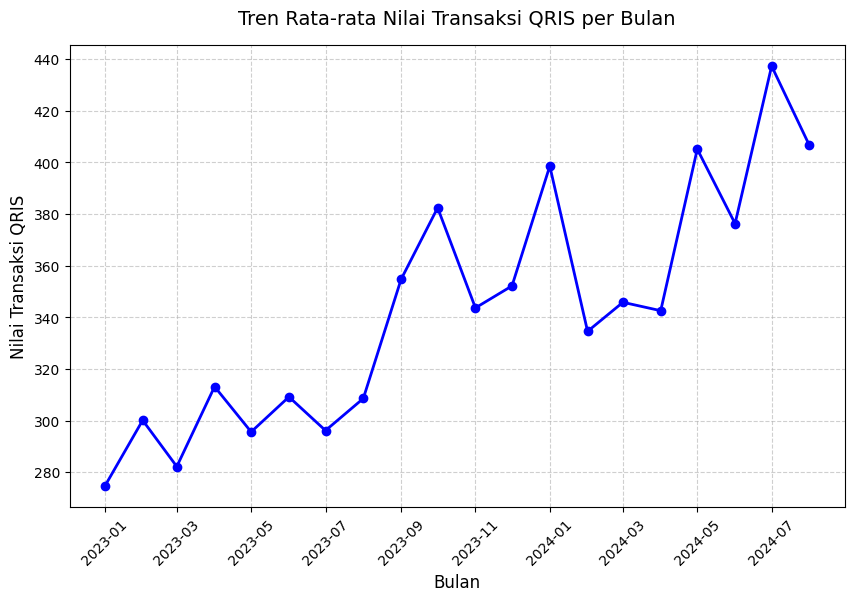

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Menghitung rata-rata Nilai_Transaksi_QRIS untuk setiap Bulan (semua provinsi digabung)
rata_per_bulan = df_makro.groupby("Bulan")["Nilai_Transaksi_QRIS"].mean()

# 2. Mengurutkan bulan dari yang paling awal ke paling akhir
rata_per_bulan = rata_per_bulan.sort_index()

# 3. Membuat diagram garis dengan titik penanda (marker)
plt.figure(figsize=(10, 6))
plt.plot(rata_per_bulan.index, rata_per_bulan.values, marker="o", color="blue", linewidth=2)

# 4. Memberikan judul dan label pada sumbu grafik
plt.title("Tren Rata-rata Nilai Transaksi QRIS per Bulan", fontsize=14, pad=15)
plt.xlabel("Bulan", fontsize=12)
plt.ylabel("Nilai Transaksi QRIS", fontsize=12)

# 5. Memutar teks tanggal pada sumbu X agar rapi dan menambahkan garis bantu (grid)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)

# 6. Menyimpan hasil grafik ke dalam file gambar berkualitas tinggi
plt.savefig("grafik_2_tren.png", dpi=150, bbox_inches="tight")

# 7. Menampilkan grafik di layar
plt.show()

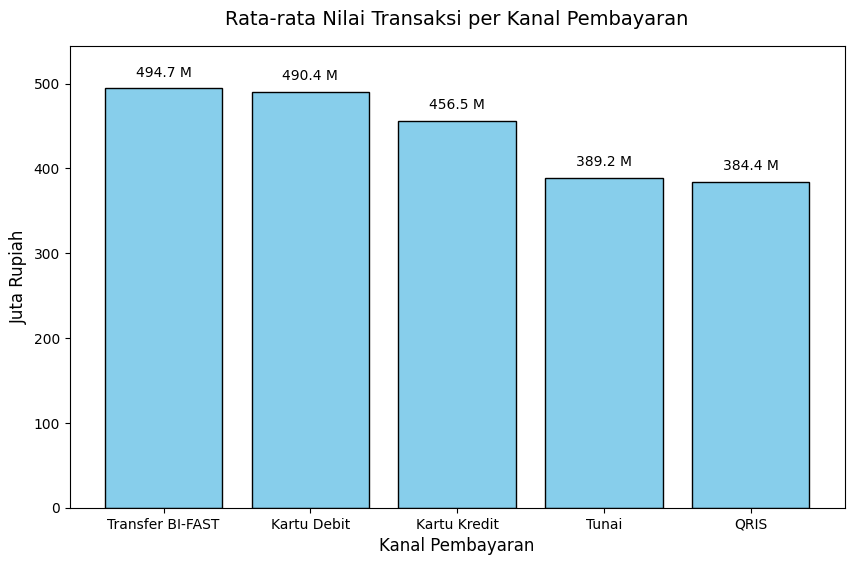

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Menghitung rata-rata Nilai_Transaksi untuk setiap Kanal_Pembayaran
rata_per_kanal = df_transaksi.groupby("Kanal_Pembayaran")["Nilai_Transaksi"].mean()

# 2. Mengurutkan nilai dari yang terbesar ke terkecil
rata_per_kanal = rata_per_kanal.sort_values(ascending=False)

# 3. Mengubah nilai ke satuan Juta Rupiah (dibagi 1.000.000)
rata_per_kanal_juta = rata_per_kanal / 1000000

# 4. Membuat diagram batang vertikal
plt.figure(figsize=(10, 6))
batang = plt.bar(rata_per_kanal_juta.index, rata_per_kanal_juta.values, color="skyblue", edgecolor="black")

# 5. Memberikan judul, label sumbu, dan menampilkan angka di atas setiap batang
plt.title("Rata-rata Nilai Transaksi per Kanal Pembayaran", fontsize=14, pad=15)
plt.ylabel("Juta Rupiah", fontsize=12)
plt.xlabel("Kanal Pembayaran", fontsize=12)

# Menambahkan angka nilai di atas masing-masing batang
for b in batang:
    tinggi = b.get_height()
    plt.text(
        b.get_x() + b.get_width() / 2,
        tinggi + 10, # Jarak angka di atas batang
        f"{tinggi:.1f} M",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Mengatur batas sumbu Y agar teks angka di atas batang tidak terpotong
plt.ylim(0, rata_per_kanal_juta.max() + 50)

# 6. Menyimpan gambar grafik dengan kualitas tinggi (DPI 150)
plt.savefig("grafik_1_kanal.png", dpi=150, bbox_inches="tight")

# 7. Menampilkan grafik di layar
plt.show()

=== MATRIKS KORELASI VARIABEL SURVEI ===
                             Usia  Frekuensi_Gunakan_QRIS  Kepuasan_Layanan_QRIS  Persepsi_Keamanan_Transaksi  Pengetahuan_BI_FAST  Niat_Menggunakan_Lagi  Loyalitas
Usia                         1.00                    0.07                   0.05                        -0.15                -0.11                   0.12       0.03
Frekuensi_Gunakan_QRIS       0.07                    1.00                  -0.09                         0.02                 0.04                  -0.07       0.02
Kepuasan_Layanan_QRIS        0.05                   -0.09                   1.00                         0.01                 0.09                   0.13      -0.09
Persepsi_Keamanan_Transaksi -0.15                    0.02                   0.01                         1.00                 0.03                   0.05       0.22
Pengetahuan_BI_FAST         -0.11                    0.04                   0.09                         0.03                 1.00    

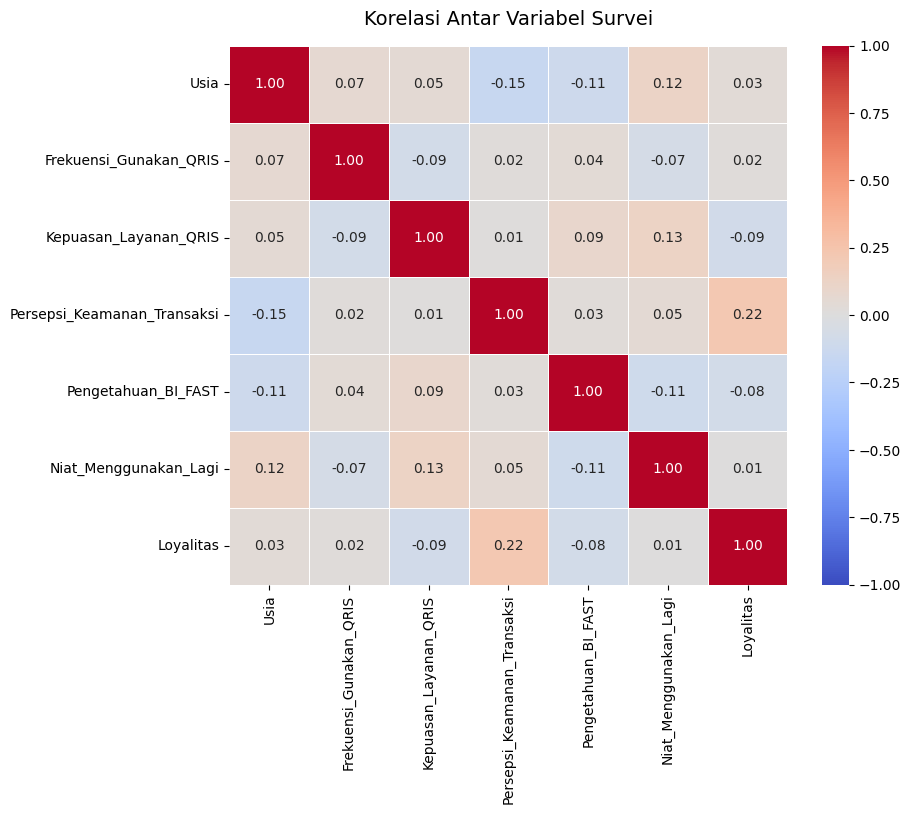

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Mengambil hanya 7 kolom angka yang ingin dianalisis korelasinya
kolom_analisis = [
    "Usia",
    "Frekuensi_Gunakan_QRIS",
    "Kepuasan_Layanan_QRIS",
    "Persepsi_Keamanan_Transaksi",
    "Pengetahuan_BI_FAST",
    "Niat_Menggunakan_Lagi",
    "Loyalitas"
]

# 2. Menghitung matriks korelasi Pearson dan membulatkan hasilnya
korelasi_survei = df_survei[kolom_analisis].corr()
korelasi_survei_bulat = korelasi_survei.round(2)

# 3. Menampilkan matriks korelasi dalam bentuk teks utuh
print("=== MATRIKS KORELASI VARIABEL SURVEI ===")
print(korelasi_survei_bulat.to_string())

# 4. Membuat visualisasi Heatmap menggunakan Seaborn
plt.figure(figsize=(9, 7))
sns.heatmap(
    korelasi_survei,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

# 5. Memberikan judul pada grafik
plt.title("Korelasi Antar Variabel Survei", fontsize=14, pad=15)

# 6. Menyimpan gambar grafik dengan resolusi tinggi (150 DPI)
plt.savefig("grafik_3_korelasi.png", dpi=150, bbox_inches="tight")

# 7. Menampilkan grafik di layar Colab
plt.show()

# **Analisis Regresi dari Sheet Makro**

Koefisien Regresi (Slope) : 0.6355
Intercept (Konstanta)    : 5.5010
R-squared (R2)           : 0.9404
Korelasi Pearson         : 0.9698


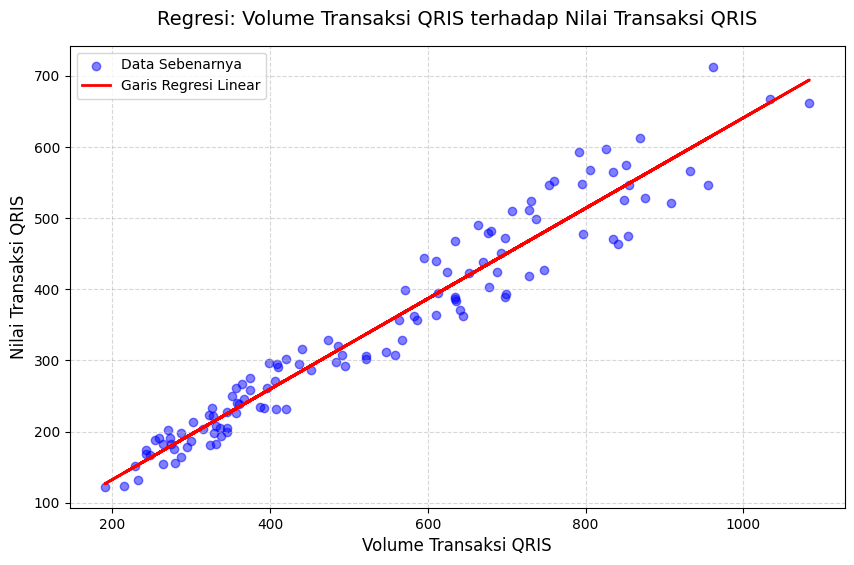

In [ ]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import pandas as pd

# 1. Menyiapkan variabel independen (X) dalam bentuk 2D dan dependen (y)
X = df_makro[["Volume_Transaksi_QRIS"]]
y = df_makro["Nilai_Transaksi_QRIS"]

# 2. Membuat objek model regresi dan melatihnya dengan seluruh data
model = LinearRegression()
model.fit(X, y)

# 3. Menghitung koefisien, intercept, dan nilai R-squared (R2)
koefisien_regresi = model.coef_[0]
intercept_regresi = model.intercept_
r_kuadrat = model.score(X, y)

# 4. Menghitung korelasi Pearson antara kedua variabel
korelasi_volume_nilai = df_makro["Volume_Transaksi_QRIS"].corr(df_makro["Nilai_Transaksi_QRIS"])

# 5. Menampilkan hasil perhitungan dengan format 4 angka di belakang koma
print(f"Koefisien Regresi (Slope) : {koefisien_regresi:.4f}")
print(f"Intercept (Konstanta)    : {intercept_regresi:.4f}")
print(f"R-squared (R2)           : {r_kuadrat:.4f}")
print(f"Korelasi Pearson         : {korelasi_volume_nilai:.4f}")

# 6. Membuat visualisasi diagram sebar (scatter plot) dari data asli
plt.figure(figsize=(10, 6))
plt.scatter(df_makro["Volume_Transaksi_QRIS"], df_makro["Nilai_Transaksi_QRIS"], color="blue", alpha=0.5, label="Data Sebenarnya")

# Membuat garis tren prediksi dari hasil regresi linear
y_prediksi = model.predict(X)
plt.plot(df_makro["Volume_Transaksi_QRIS"], y_prediksi, color="red", linewidth=2, label="Garis Regresi Linear")

# 7. Mengatur judul grafik, label sumbu X dan Y, serta menambahkan legenda dan grid
plt.title("Regresi: Volume Transaksi QRIS terhadap Nilai Transaksi QRIS", fontsize=14, pad=15)
plt.xlabel("Volume Transaksi QRIS", fontsize=12)
plt.ylabel("Nilai Transaksi QRIS", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)

# 8. Menyimpan gambar grafik dengan resolusi 150 DPI
plt.savefig("grafik_4_regresi.png", dpi=150, bbox_inches="tight")

# 9. Menampilkan grafik di layar
plt.show()

# **Report**

5A. Kerangla + tabel+ gambar visualisasi

In [ ]:
!pip install -q python-docx

import docx
from docx.shared import Inches, Pt
from google.colab import files
import pandas as pd

# 1. Membuat dokumen baru
doc = docx.Document()

# Judul utama laporan
judul_utama = doc.add_paragraph()
run_judul = judul_utama.add_run("Laporan Analisis Data Latihan Bank Indonesia")
run_judul.font.size = Pt(18)
run_judul.bold = True

# ==========================================
# BAGIAN A: STATISTIK DESKRIPTIF
# ==========================================
doc.add_heading("A. Statistik Deskriptif", level=1)

# Fungsi bantu format angka gaya Indonesia
def format_indonesia(angka, desimal=2):
    if pd.isna(angka):
        return "-"
    # Format angka dengan desimal titik terlebih dahulu
    teks_format = f"{angka:,.{desimal}f}"
    # Ganti pemisah ribuan koma menjadi sementara, titik desimal menjadi koma, lalu sementara menjadi titik
    teks_indo = teks_format.replace(",", "temp").replace(".", ",").replace("temp", ".")
    return teks_indo

# --- A.1 Data Transaksi ---
doc.add_heading("A.1 Data Transaksi", level=2)
tabel_transaksi = doc.add_table(rows=1, cols=3)
tabel_transaksi.style = 'Table Grid'

# Header tabel
hdr_cells = tabel_transaksi.rows[0].cells
hdr_cells[0].text = 'Statistik'
hdr_cells[1].text = 'Nilai_Transaksi'
hdr_cells[2].text = 'Biaya_Admin'

# Atur ukuran font header
for cell in hdr_cells:
    for paragraph in cell.paragraphs:
        for run in paragraph.runs:
            run.font.size = Pt(8)
            run.bold = True

# Isi tabel transaksi (0 angka desimal)
for idx in ringkasan_transaksi.index:
    row_cells = tabel_transaksi.add_row().cells
    row_cells[0].text = str(idx)
    row_cells[1].text = format_indonesia(ringkasan_transaksi.loc[idx, 'Nilai_Transaksi'], desimal=0)
    row_cells[2].text = format_indonesia(ringkasan_transaksi.loc[idx, 'Biaya_Admin'], desimal=0)

    # Atur ukuran font isi tabel
    for cell in row_cells:
        for paragraph in cell.paragraphs:
            for run in paragraph.runs:
                run.font.size = Pt(8)

doc.add_paragraph() # Paragraf kosong

# --- A.2 Data Survei Persepsi ---
doc.add_heading("A.2 Data Survei Persepsi", level=2)
kolom_survei = ringkasan_survei.columns.tolist()
tabel_survei = doc.add_table(rows=1, cols=len(kolom_survei) + 1)
tabel_survei.style = 'Table Grid'

# Header tabel
hdr_cells = tabel_survei.rows[0].cells
hdr_cells[0].text = 'Statistik'
for i, col in enumerate(kolom_survei):
    hdr_cells[i + 1].text = col

for cell in hdr_cells:
    for paragraph in cell.paragraphs:
        for run in paragraph.runs:
            run.font.size = Pt(8)
            run.bold = True

# Isi tabel survei (2 angka desimal)
for idx in ringkasan_survei.index:
    row_cells = tabel_survei.add_row().cells
    row_cells[0].text = str(idx)
    for i, col in enumerate(kolom_survei):
        row_cells[i + 1].text = format_indonesia(ringkasan_survei.loc[idx, col], desimal=2)

    for cell in row_cells:
        for paragraph in cell.paragraphs:
            for run in paragraph.runs:
                run.font.size = Pt(8)

doc.add_paragraph() # Paragraf kosong

# --- A.3 Data Makro Inklusi Keuangan ---
doc.add_heading("A.3 Data Makro Inklusi Keuangan", level=2)
kolom_makro = ringkasan_makro.columns.tolist()
tabel_makro = doc.add_table(rows=1, cols=len(kolom_makro) + 1)
tabel_makro.style = 'Table Grid'

# Header tabel
hdr_cells = tabel_makro.rows[0].cells
hdr_cells[0].text = 'Statistik'
for i, col in enumerate(kolom_makro):
    hdr_cells[i + 1].text = col

for cell in hdr_cells:
    for paragraph in cell.paragraphs:
        for run in paragraph.runs:
            run.font.size = Pt(8)
            run.bold = True

# Isi tabel makro (2 angka desimal)
for idx in ringkasan_makro.index:
    row_cells = tabel_makro.add_row().cells
    row_cells[0].text = str(idx)
    for i, col in enumerate(kolom_makro):
        row_cells[i + 1].text = format_indonesia(ringkasan_makro.loc[idx, col], desimal=2)

    for cell in row_cells:
        for paragraph in cell.paragraphs:
            for run in paragraph.runs:
                run.font.size = Pt(8)

doc.add_paragraph() # Paragraf kosong

# ==========================================
# BAGIAN B: VISUALISASI
# ==========================================
doc.add_heading("B. Visualisasi", level=1)

# Daftar gambar dan keterangannya
gambar_list = [
    ("grafik_1_kanal.png", "Gambar 1. Rata-rata nilai transaksi per kanal pembayaran."),
    ("grafik_2_tren.png", "Gambar 2. Tren rata-rata nilai transaksi QRIS per bulan."),
    ("grafik_3_korelasi.png", "Gambar 3. Korelasi antar variabel survei."),
    ("grafik_4_regresi.png", "Gambar 4. Regresi volume transaksi QRIS terhadap nilai transaksi QRIS.")
]

for path_gambar, keterangan in gambar_list:
    # Tambahkan gambar dengan lebar 5,5 inci
    doc.add_picture(path_gambar, width=Inches(5.5))
    # Tambahkan kalimat keterangan di bawah gambar
    p_ket = doc.add_paragraph(keterangan)
    p_ket.paragraph_format.space_after = Pt(12) # Jarak pemisah antar gambar

# 8. Menyimpan dokumen ke file Word
nama_laporan = "laporan_analisis_bi.docx"
doc.save(nama_laporan)
print("Dokumen Word berhasil dibuat:", nama_laporan)

# 9. Mengunduh file laporan otomatis
files.download(nama_laporan)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 5.4 MB/s eta 0:00:00
Dokumen Word berhasil dibuat: laporan_analisis_bi.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

5B. Tambah penjelasan kedalam laporan

In [ ]:
import docx
from docx.shared import Inches, Pt
from google.colab import files
import pandas as pd

# 1. Membuat dokumen baru
doc = docx.Document()

# ==========================================
# JUDUL UTAMA
# ==========================================
judul_utama = doc.add_paragraph()
run_judul = judul_utama.add_run("Laporan Analisis Data Latihan Bank Indonesia")
run_judul.font.size = Pt(18)
run_judul.bold = True

# ==========================================
# PENDAHULUAN
# ==========================================
doc.add_heading("Pendahuluan", level=1)
paragraf_pendahuluan = (
    "Laporan ini merangkum hasil analisis tiga kumpulan data latihan yang telah dibersihkan: "
    "data transaksi (194 baris, periode Januari sampai Desember 2024), data survei persepsi "
    "responden (146 baris), dan data makro inklusi keuangan di enam provinsi (120 baris, "
    "periode Januari 2023 sampai Agustus 2024). Analisis mencakup statistik deskriptif, "
    "visualisasi, korelasi, dan regresi linear sederhana."
)
doc.add_paragraph(paragraf_pendahuluan)
doc.add_paragraph() # Paragraf kosong

# ==========================================
# BAGIAN A: STATISTIK DESKRIPTIF
# ==========================================
doc.add_heading("A. Statistik Deskriptif", level=1)

# Fungsi bantu format angka gaya Indonesia
def format_indonesia(angka, desimal=2):
    if pd.isna(angka):
        return "-"
    teks_format = f"{angka:,.{desimal}f}"
    teks_indo = teks_format.replace(",", "temp").replace(".", ",").replace("temp", ".")
    return teks_indo

# --- A.1 Data Transaksi ---
doc.add_heading("A.1 Data Transaksi", level=2)
tabel_transaksi = doc.add_table(rows=1, cols=3)
tabel_transaksi.style = 'Table Grid'

# Header tabel
hdr_cells = tabel_transaksi.rows[0].cells
hdr_cells[0].text = 'Statistik'
hdr_cells[1].text = 'Nilai_Transaksi'
hdr_cells[2].text = 'Biaya_Admin'

for cell in hdr_cells:
    for paragraph in cell.paragraphs:
        for run in paragraph.runs:
            run.font.size = Pt(8)
            run.bold = True

# Isi tabel transaksi (0 angka desimal)
for idx in ringkasan_transaksi.index:
    row_cells = tabel_transaksi.add_row().cells
    row_cells[0].text = str(idx)
    row_cells[1].text = format_indonesia(ringkasan_transaksi.loc[idx, 'Nilai_Transaksi'], desimal=0)
    row_cells[2].text = format_indonesia(ringkasan_transaksi.loc[idx, 'Biaya_Admin'], desimal=0)

    for cell in row_cells:
        for paragraph in cell.paragraphs:
            for run in paragraph.runs:
                run.font.size = Pt(8)

doc.add_paragraph() # Paragraf kosong

# --- A.2 Data Survei Persepsi ---
doc.add_heading("A.2 Data Survei Persepsi", level=2)
kolom_survei = ringkasan_survei.columns.tolist()
tabel_survei = doc.add_table(rows=1, cols=len(kolom_survei) + 1)
tabel_survei.style = 'Table Grid'

# Header tabel
hdr_cells = tabel_survei.rows[0].cells
hdr_cells[0].text = 'Statistik'
for i, col in enumerate(kolom_survei):
    hdr_cells[i + 1].text = col

for cell in hdr_cells:
    for paragraph in cell.paragraphs:
        for run in paragraph.runs:
            run.font.size = Pt(8)
            run.bold = True

# Isi tabel survei (2 angka desimal)
for idx in ringkasan_survei.index:
    row_cells = tabel_survei.add_row().cells
    row_cells[0].text = str(idx)
    for i, col in enumerate(kolom_survei):
        row_cells[i + 1].text = format_indonesia(ringkasan_survei.loc[idx, col], desimal=2)

    for cell in row_cells:
        for paragraph in cell.paragraphs:
            for run in paragraph.runs:
                run.font.size = Pt(8)

doc.add_paragraph() # Paragraf kosong

# --- A.3 Data Makro Inklusi Keuangan ---
doc.add_heading("A.3 Data Makro Inklusi Keuangan", level=2)
kolom_makro = ringkasan_makro.columns.tolist()
tabel_makro = doc.add_table(rows=1, cols=len(kolom_makro) + 1)
tabel_makro.style = 'Table Grid'

# Header tabel
hdr_cells = tabel_makro.rows[0].cells
hdr_cells[0].text = 'Statistik'
for i, col in enumerate(kolom_makro):
    hdr_cells[i + 1].text = col

for cell in hdr_cells:
    for paragraph in cell.paragraphs:
        for run in paragraph.runs:
            run.font.size = Pt(8)
            run.bold = True

# Isi tabel makro (2 angka desimal)
for idx in ringkasan_makro.index:
    row_cells = tabel_makro.add_row().cells
    row_cells[0].text = str(idx)
    for i, col in enumerate(kolom_makro):
        row_cells[i + 1].text = format_indonesia(ringkasan_makro.loc[idx, col], desimal=2)

    for cell in row_cells:
        for paragraph in cell.paragraphs:
            for run in paragraph.runs:
                run.font.size = Pt(8)

doc.add_paragraph() # Paragraf kosong

# ==========================================
# BAGIAN B: VISUALISASI
# ==========================================
doc.add_heading("B. Visualisasi", level=1)

# Daftar gambar dan keterangannya
gambar_list = [
    ("grafik_1_kanal.png", "Gambar 1. Rata-rata nilai transaksi per kanal pembayaran."),
    ("grafik_2_tren.png", "Gambar 2. Tren rata-rata nilai transaksi QRIS per bulan."),
    ("grafik_3_korelasi.png", "Gambar 3. Korelasi antar variabel survei."),
    ("grafik_4_regresi.png", "Gambar 4. Regresi volume transaksi QRIS terhadap nilai transaksi QRIS.")
]

for path_gambar, keterangan in gambar_list:
    doc.add_picture(path_gambar, width=Inches(5.5))
    p_ket = doc.add_paragraph(keterangan)
    p_ket.paragraph_format.space_after = Pt(12) # Jarak pemisah

doc.add_paragraph() # Paragraf kosong

# ==========================================
# BAGIAN C: CATATAN DATA
# ==========================================
doc.add_heading("C. Catatan Data", level=1)

catatan_data_list = [
    ("Berkas latihan semula berisi 200 baris data transaksi, 150 baris data survei, dan 120 baris data makro. "
     "Setelah pembersihan, jumlah baris menjadi 194, 146, dan 120."),
    ("Aturan pembersihan yang digunakan: tanggal bergaris miring dibaca sebagai hari/bulan/tahun; "
     "usia dianggap wajar pada rentang 17 sampai 100 tahun; skala frekuensi penggunaan 1 sampai 7 dan skor "
     "survei lainnya 1 sampai 5; nilai negatif dan nilai ekstrem dikosongkan lalu diisi dengan median; "
     "sel teks yang kosong diisi dengan modus; data makro yang kosong diisi dengan median per provinsi."),
    ("Keputusan pengisian median memengaruhi hasil. Pada kolom Nilai_Transaksi, nilai 419.292.000 muncul 10 "
     "kali karena berasal dari pengisian median, sehingga nilai tengah (50%) kolom tersebut sama dengan angka ini. "
     "Rata-rata dan sebaran kolom tersebut perlu dibaca dengan kehati-hatian.")
]

for teks_catatan in catatan_data_list:
    doc.add_paragraph(teks_catatan)

doc.add_paragraph() # Paragraf kosong

# ==========================================
# BAGIAN D: TEMUAN DAN KESIMPULAN
# ==========================================
doc.add_heading("D. Temuan dan Kesimpulan", level=1)

temuan_list = [
    ("D.1 Kanal Pembayaran",
     "Rata-rata nilai transaksi tertinggi terdapat pada kanal Transfer BI-FAST (494,75 juta rupiah), disusul Kartu Debit "
     "(490,39 juta) dan Kartu Kredit (456,53 juta). Rata-rata terendah terdapat pada Tunai (389,20 juta) dan QRIS "
     "(384,35 juta). Perlu dicatat bahwa QRIS adalah kanal dengan jumlah transaksi terbanyak (67 dari 194 transaksi)."),
    ("D.2 Tren Transaksi QRIS",
     "Rata-rata nilai transaksi QRIS per bulan cenderung naik, dari 274,62 pada Januari 2023 menjadi 406,55 pada "
     "Agustus 2024, dengan puncak 437,30 pada Juli 2024. Kenaikan tersebut tidak mulus karena terdapat naik-turun antarbulan."),
    ("D.3 Korelasi Variabel Survei",
     "Rata-rata skor survei berada di sekitar tengah skala, yaitu 2,85 sampai 3,16 pada skala 1 sampai 5 (frekuensi "
     "penggunaan QRIS rata-rata 3,96 pada skala 1 sampai 7). Seluruh korelasi antar variabel survei tergolong lemah. "
     "Korelasi tertinggi adalah Persepsi Keamanan Transaksi dengan Loyalitas (0,22) dan korelasi terendah adalah Usia "
     "dengan Persepsi Keamanan Transaksi (-0,15). Dengan demikian tidak ditemukan hubungan yang kuat antar variabel survei."),
    ("D.4 Regresi Data Makro",
     "Pada data makro, regresi linear sederhana menunjukkan bahwa setiap kenaikan 1 poin Volume Transaksi QRIS diikuti "
     "kenaikan sekitar 0,64 poin Nilai Transaksi QRIS (koefisien 0,6355). Nilai R-kuadrat sebesar 0,9404 dan korelasi "
     "sebesar 0,9698 menunjukkan hubungan yang sangat kuat. Pada volume besar (di atas sekitar 800), titik data lebih "
     "menyebar dari garis sehingga perkiraan pada rentang tersebut kurang presisi. Hubungan ini menunjukkan keterkaitan, "
     "bukan bukti sebab-akibat."),
    ("D.5 Kesimpulan",
     "Secara ringkas: (1) nilai transaksi QRIS cenderung naik sepanjang periode pengamatan; (2) volume dan nilai transaksi "
     "QRIS berkaitan sangat kuat; (3) variabel survei tidak saling berhubungan secara kuat; (4) hasil pada data transaksi "
     "perlu dibaca dengan memperhatikan pengisian median.")
]

for sub_judul, teks_isi in temuan_list:
    doc.add_heading(sub_judul, level=2)
    doc.add_paragraph(teks_isi)

# ==========================================
# SIMPAN DAN UNDUH FILE
# ==========================================
nama_laporan_lengkap = "laporan_analisis_bi_lengkap.docx"
doc.save(nama_laporan_lengkap)
print("Dokumen Word Lengkap berhasil dibuat:", nama_laporan_lengkap)

files.download(nama_laporan_lengkap)

Dokumen Word Lengkap berhasil dibuat: laporan_analisis_bi_lengkap.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>